# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170249          # <-- your full roll number
NAME = "Shivansh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170249   Name: Shivansh   Fingerprint: A280D0AF   Tickets: 16

Ticket_ID                                                                                   Ticket_Text
      T01                        I cannot access the VPN since yesterday. It works on another computer.
      T02 I am unable to use the printer before the assignment deadline. The same problem occurs again.
      T03                                      The WiFi has stopped syncing. Is there another solution?
      T04                                                                   Ticket #4521 is still open.
      T05                 Student portal failed to open when connected to campus Wi-Fi. This is urgent.
      T06                                    The Python keeps disconnecting. I don't know what changed.
      T07                 Server was working yesterday after resetting my password. Can you check this?
      T08                                                   The state-of-the-art lab (La

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Q1: Preprocessing all tickets

rows = []

# Run process_ticket() on every ticket
for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

# Create the summary table
q1_table = pd.DataFrame(rows)

# Add TOTAL row
total = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation": q1_table["Punctuation"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": q1_table["Unique Tokens"].sum(),
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total])],
    ignore_index=True
)

# Display the table
display(q1_table)


,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,15,2,6,14,7
1,T02,2,18,2,9,15,7
2,T03,2,11,2,4,11,5
3,T04,1,7,2,1,7,4
4,T05,2,15,2,5,13,8
5,T06,2,12,2,4,11,6
6,T07,2,14,2,6,14,6
7,T08,1,9,3,2,9,4
8,T09,2,12,2,2,11,8
9,T10,2,13,2,5,12,6


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
import re
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
# Patterns
long_words = r"\b[A-Za-z]{6,}\b"
numbers = r"\b\d+(?:\.\d+)+|\b\d+(?:,\d{3})*\b"
capitalized = r"\b[A-Z][A-Za-z]*\b"
vowel_words = r"\b[AEIOUaeiou][A-Za-z]*\b"

email = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url = r"(?:https?://|www\.)[^\s]+"
phone = r"(?<!\d)(?:\+91[- ]?)?(?:\d{5}[- ]?\d{5}|\d{3}[- ]?\d{3}[- ]?\d{4})(?!\d)"

# Test on TEST_LINES
for line in TEST_LINES:
    print("=" * 70)
    print("RAW:", line)
    print("Long words:", re.findall(long_words, line))
    print("Numbers:", re.findall(numbers, line))
    print("Capitalized words:", re.findall(capitalized, line))
    print("Vowel words:", re.findall(vowel_words, line))

    replaced = re.sub(email, "<EMAIL>", line)
    replaced = re.sub(url, "<URL>", replaced)
    replaced = re.sub(phone, "<PHONE>", replaced)
    print("Replaced:", replaced)

# Apply to all raw tickets
q2_rows = []

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    q2_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Long Words": re.findall(long_words, text),
        "Numbers": re.findall(numbers, text),
        "Capitalized Words": re.findall(capitalized, text),
        "Vowel Words": re.findall(vowel_words, text),
        "Replaced Text": re.sub(phone, "<PHONE>",
                         re.sub(url, "<URL>",
                         re.sub(email, "<EMAIL>", text)))
    })

q2_table = pd.DataFrame(q2_rows)
display(q2_table)


RAW: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Long words: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Vowel words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Replaced: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
RAW: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Long words: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel words: ['or', 'is']
Replaced: Call <PHONE>, <PHONE> or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
RAW: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Long words: []
Numbers: ['5.30']
Capitalized words: ['The']
Vowel words: ['of', 'art', 'isn', 'open', 'in', 'at']
Replaced: The state-of-the-art lab isn't open; log-in at 5.30 

,Ticket_ID,Long Words,Numbers,Capitalized Words,Vowel Words,Replaced Text
0,T01,"[cannot, access, yesterday, another, computer]",[],"[I, VPN, It]","[I, access, It, on, another]",I cannot access the VPN since yesterday. It wo...
1,T02,"[unable, printer, before, assignment, deadline...",[],"[I, The]","[I, am, unable, use, assignment, occurs, again]",I am unable to use the printer before the assi...
2,T03,"[stopped, syncing, another, solution]",[],"[The, WiFi, Is]","[Is, another]",The WiFi has stopped syncing. Is there another...
3,T04,[Ticket],[4521],[Ticket],"[is, open]",Ticket #4521 is still open.
4,T05,"[Student, portal, failed, connected, campus, u...",[],"[Student, Wi, Fi, This]","[open, is, urgent]",Student portal failed to open when connected t...
5,T06,"[Python, disconnecting, changed]",[],"[The, Python, I]",[I],The Python keeps disconnecting. I don't know w...
6,T07,"[Server, working, yesterday, resetting, password]",[],"[Server, Can]",[after],Server was working yesterday after resetting m...
7,T08,[closed],[3],"[The, Lab]","[of, art, is]",The state-of-the-art lab (Lab-3) is closed.
8,T09,"[stopped, responding, yesterday, another, comp...",[],"[Wifi, It]","[It, on, another]",Wifi stopped responding since yesterday. It wo...
9,T10,"[crashes, opening, changed]",[],"[The, I]","[e, opening, I]",The e-mail crashes while opening. I don't know...


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:

import nltk
from nltk.tokenize import RegexpTokenizer, word_tokenize

# --------------------------------------------------
# 1. Construct the Regular Expression Pattern
# --------------------------------------------------
# The pattern matches:
# 1. Email addresses
# 2. URLs
# 3. Phone numbers
# 4. Decimals and version numbers
# 5. Hyphenated words
# 6. Contractions and possessives
# 7. Standard words
# 8. Integers with commas
# 9. Individual punctuation characters

pattern = r'''(?x)
    # 1. Email addresses
    (?:[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,})

    # 2. URLs
    | (?:https?://\S+|www\.\S+)

    # 3. Phone numbers
    | (?:\+?91[-.\s]?)?\d{5}[-.\s]?\d{5}
    | \d{4}-\d{3}-\d{4}

    # 4. Decimals and version numbers
    | \b\d+(?:\.\d+)+\b

    # 5. Hyphenated and multi-hyphenated words
    | \b[a-zA-Z]+(?:-[a-zA-Z]+)+\b

    # 6. Contractions and possessives
    | \b[a-zA-Z]+(?:['’][a-zA-Z]+)+\b

    # 7. Standard words
    | \b[a-zA-Z]+\b

    # 8. Integers with optional comma-separated groups
    | \b\d{1,3}(?:,\d{3})*\b

    # 9. Any other non-whitespace character
    | \S
'''

# Create the custom tokenizer
tokenizer = RegexpTokenizer(pattern)


# --------------------------------------------------
# 2. Define the Custom Tokenization Function
# --------------------------------------------------
def my_tokenize(text):
    return tokenizer.tokenize(text)


# --------------------------------------------------
# 3. Test the Tokenizer on TEST_LINES
# --------------------------------------------------
print("=== TESTING CUSTOM TOKENIZER ON TEST LINES ===")

for i, line in enumerate(TEST_LINES, start=1):
    custom_toks = my_tokenize(line)
    nltk_toks = word_tokenize(line)

    print(f"\nLine {i}: {line}")
    print(f"  my_tokenize:   {custom_toks}")
    print(f"  word_tokenize: {nltk_toks}")


# --------------------------------------------------
# 4. Compare Tokenization on Generated Tickets
# --------------------------------------------------
print("\n=== COMPARING TOKENIZATION ON TICKETS ===")

different_count = 0

for _, row in df.iterrows():
    t_text = row["Ticket_Text"]

    custom_toks = my_tokenize(t_text)
    nltk_toks = word_tokenize(t_text)

    # Normalize case to focus on tokenization differences
    custom_norm = [token.lower() for token in custom_toks]
    nltk_norm = [token.lower() for token in nltk_toks]

    # Compare the normalized token lists
    if custom_norm != nltk_norm:
        different_count += 1

        print(f"\nTicket ID: {row['Ticket_ID']}")
        print(f"Text: {t_text}")
        print(f"  my_tokenize:   {custom_toks}")
        print(f"  word_tokenize: {nltk_toks}")


# --------------------------------------------------
# 5. Display the Final Results
# --------------------------------------------------
print("\n=== FINAL RESULTS ===")
print(f"Total tickets: {len(df)}")
print(
    f"Total tickets tokenized differently: "
    f"{different_count} out of {len(df)}"
)
print(
    f"Total tickets tokenized identically: "
    f"{len(df) - different_count} out of {len(df)}"
)


=== TESTING CUSTOM TOKENIZER ON TEST LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3: The state-of-the-ar

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [11]:
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# 1. Collect all unique final tokens across all tickets
all_final_tokens = []
for i, row in df.iterrows():
    res = process_ticket(row["Ticket_Text"])
    all_final_tokens.extend(res["final"])

unique_final_tokens = sorted(list(set(all_final_tokens)))

# Initialize the stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# A custom RegexpStemmer that strips common suffixes like 'ing', 'ly', 'es', or 's'
regexp = RegexpStemmer('ing$|ly$|es$|s$', min=4)
lemmatizer = WordNetLemmatizer()

# Helper function to map NLTK POS tags to WordNet POS tags
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Get POS tags for all unique final tokens
pos_tags = nltk.pos_tag(unique_final_tokens)
word_pos_map = dict(pos_tags)

comparison_data = []

for word in unique_final_tokens:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp.stem(word)

    # Get WordNet POS tag for lemmatization
    nltk_tag = word_pos_map.get(word, 'N')
    wn_tag = get_wordnet_pos(nltk_tag)
    wn_lemma = lemmatizer.lemmatize(word, pos=wn_tag)

    # Only add to the table if there is any difference between the stemmers/lemmatizer
    if len({p_stem, l_stem, r_stem, wn_lemma}) > 1:
        comparison_data.append({
            "Original Word": word,
            "POS Tag": nltk_tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp (Custom)": r_stem,
            "WordNet Lemma": wn_lemma
        })

q4_table = pd.DataFrame(comparison_data)
display(q4_table)

,Original Word,POS Tag,Porter,Lancaster,Regexp (Custom),WordNet Lemma
0,access,NN,access,access,acces,access
1,another,DT,anoth,anoth,another,another
2,assignment,NN,assign,assign,assignment,assignment
3,campus,NN,campu,camp,campu,campus
4,changed,VBD,chang,chang,changed,change
5,closed,VBD,close,clos,closed,close
6,computer,NN,comput,comput,computer,computer
7,connected,VBN,connect,connect,connected,connect
8,deadline,VBP,deadlin,deadlin,deadline,deadline
9,error,NN,error,er,error,error


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== CORPUS STATISTICS ===
S1 -> Total Tokens: 186, Unique Tokens: 88, TTR: 0.4731
S2 -> Total Tokens: 155, Unique Tokens: 83, TTR: 0.5355
S3 -> Total Tokens: 93, Unique Tokens: 58, TTR: 0.6237
S4 -> Total Tokens: 93, Unique Tokens: 55, TTR: 0.5914

=== TOP 10 WORDS ===
S1: [('.', 26), ('the', 11), ('is', 7), ('yesterday', 6), ('it', 5), ('works', 5), ('another', 5), ('i', 4), ('on', 4), ('computer', 4)]
S3: [('yesterday', 6), ('works', 5), ('another', 5), ('computer', 4), ('stopped', 4), ('since', 3), ('syncing', 3), ('python', 3), ('vpn', 2), ('printer', 2)]

=== TOP 5 BIGRAMS ===
S1 Bigrams: [(('.', 'the'), 7), (('yesterday', '.'), 5), (('.', 'it'), 5), (('it', 'works'), 4), (('works', 'on'), 4)]
S3 Bigrams: [(('works', 'another'), 4), (('another', 'computer'), 4), (('since', 'yesterday'), 3), (('stopped', 'syncing'), 3), (('yesterday', 'works'), 2)]


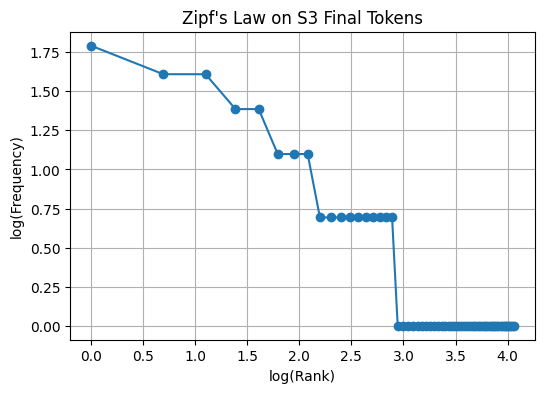

In [10]:
import nltk
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import string

# Prepare sets
STOP = set(stopwords.words('english'))
porter = PorterStemmer()

def is_punct(token):
    return all(ch in string.punctuation for ch in token)

# 1. Reconstruct sets
# S1: All tokens
all_sentences = []
for t_text in df['Ticket_Text']:
    all_sentences.extend(sent_tokenize(t_text))

S1 = [t.lower() for s in all_sentences for t in word_tokenize(s)]

# S2: No punctuation
S2 = [t for t in S1 if not is_punct(t)]

# S3: Final tokens (No punctuation, No stopwords)
S3 = [t for t in S2 if t not in STOP]

# S4: S3 after Porter stemming
S4 = [porter.stem(t) for t in S3]

# Helper for stats
def get_stats(tokens):
    tot = len(tokens)
    uniq = len(set(tokens))
    ttr = uniq / tot if tot > 0 else 0
    return tot, uniq, ttr

print("=== CORPUS STATISTICS ===")
for name, tokens in zip(["S1", "S2", "S3", "S4"], [S1, S2, S3, S4]):
    tot, uniq, ttr = get_stats(tokens)
    print(f"{name} -> Total Tokens: {tot}, Unique Tokens: {uniq}, TTR: {ttr:.4f}")

# Top 10 words of S1 and S3
print("\n=== TOP 10 WORDS ===")
print("S1:", Counter(S1).most_common(10))
print("S3:", Counter(S3).most_common(10))

# Top 5 bigrams of S1 and S3
print("\n=== TOP 5 BIGRAMS ===")
S1_bigrams = list(nltk.bigrams(S1))
S3_bigrams = list(nltk.bigrams(S3))
print("S1 Bigrams:", Counter(S1_bigrams).most_common(5))
print("S3 Bigrams:", Counter(S3_bigrams).most_common(5))

# Plot log(rank) vs log(frequency) for S3
counts = Counter(S3)
frequencies = sorted(counts.values(), reverse=True)
ranks = list(range(1, len(frequencies) + 1))

plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(frequencies), marker='o', linestyle='-')
plt.title("Zipf's Law on S3 Final Tokens")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*